# Spá vs. útkoma – hversu traustar eru fjárlagaáætlanir?

**Spurningar:**
1. Héldu útgjöldin 2025 sig innan fjárlaga? *(fjárheimildir vs. raun)*
2. Hversu nálægt var **áætlunin** fyrir 2027 því sem svo kom í **frumvarpinu**?
3. Hvað breyttist í meðförum Alþingis á fjárlögum 2026?

**Hugmyndin:** Sama árið birtist í *tveimur útgáfum* af gögnunum, með ólíkri stöðu:

| Ár | Í frumvarpi 2026 (birt sept. 2025) | Í frumvarpi 2027 (birt sept. 2026) |
|---|---|---|
| 2025 | Fjárlög (heimild) | **Ríkisreikningur (raun)** |
| 2026 | Frumvarp | **Fjárlög (samþykkt)** |
| 2027 | Áætlun | **Frumvarp** |
| 2028 | Áætlun | Áætlun |

Með því að setja útgáfurnar hlið við hlið sjáum við hversu mikið tölurnar breyttust eftir því sem nær dró. Greinendur kalla þetta *vintage*-samanburð.

Upphæðir í **milljónum króna**, á **nafnvirði**.

## 1. Uppsetning og lestur gagna

Skrárnar tvær eru á ólíku sniði:
- 2026 er **CSV** → `pd.read_csv` með íslensku stillingunum (`sep=";"`, `decimal=","`).
- 2027 er **Excel** → `pd.read_excel`. Excel geymir tölur sem tölur, svo þar þarf engar sérstillingar.

Við bætum dálkinum **`Útgáfa`** við hvora töflu, svo við vitum úr hvorri skrá hver lína kemur þegar við sameinum þær.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.1f}".format)
pd.set_option("display.width", 200)

GOGN = Path("gogn")

frv26 = pd.read_csv(next(GOGN.glob("fjarlog_2026*.csv")), sep=";", decimal=",", encoding="utf-8-sig")
frv27 = pd.read_excel(next(GOGN.glob("*2027*.xlsx")))

frv26["Útgáfa"] = "Frv. 2026"
frv27["Útgáfa"] = "Frv. 2027"

print(frv26.shape, frv27.shape)

(29478, 11) (28660, 11)


**Athugaðu alltaf hvort dálkarnir séu eins** áður en þú sameinar tvær skrár. Ef nöfnin væru ólík (t.d. `Upphæð` vs `Upphaed`) myndi `concat` búa til tvo aðskilda dálka og fylla hinn með NaN.

In [2]:
list(frv26.columns) == list(frv27.columns)

True

## 2. Sameina í eina töflu

`pd.concat([a, b])` staflar töflum hvorri ofan á aðra (eins og að líma eitt Excel-blað undir annað). `ignore_index=True` býr til nýtt línunúmer frá 0.

Svo síum við strax á **`Heildarútgjöld`**. Sama upphæð birtist í mörgum `TegundNota`-línum, svo án þessarar síu tvítelst allt (sjá `greining.ipynb`).

In [3]:
gogn = pd.concat([frv26, frv27], ignore_index=True)
heild = gogn[gogn["TegundNota"] == "Heildarútgjöld"]

MALEFNASVID = ["27", "28", "29", "30", "31", "32"]
fel = heild[heild["Málefnasvið"].str[:2].isin(MALEFNASVID)]

len(gogn), len(heild), len(fel)

(58138, 7903, 1316)

## 3. Heildaryfirlit: hvert ár í báðum útgáfum

`groupby(["Ár", "Útgáfa"])` hópar eftir tveimur dálkum í einu. `.agg(...)` leyfir okkur að reikna mismunandi hluti í hverjum dálki: fyrsta gildið af `Afurð` (hvers konar tala) og summuna af `Upphæð`.

`.unstack("Útgáfa")` færir útgáfurnar úr línum yfir í dálka, svo auðvelt sé að bera saman.

In [4]:
yfirlit = (
    heild.groupby(["Ár", "Útgáfa"])
    .agg(tegund=("Afurð", "first"), mkr=("Upphæð", "sum"))
    .unstack("Útgáfa")
)
yfirlit

tegund                          mkr            
Útgáfa        Frv. 2026        Frv. 2027   Frv. 2026   Frv. 2027
Ár                                                              
2024    Ríkisreikningur              NaN 1,491,095.1         NaN
2025            Fjárlög  Ríkisreikningur 1,545,639.5 1,694,644.3
2026           Frumvarp          Fjárlög 1,672,186.3 1,685,193.8
2027             Áætlun         Frumvarp 1,670,061.2 1,765,081.8
2028             Áætlun           Áætlun 1,700,003.4 1,778,458.6
2029                NaN           Áætlun         NaN 1,809,552.0

**Lestu töfluna lárétt:** Í hverri línu sérðu sama ár eins og það leit út í september 2025 (vinstri) og september 2026 (hægri).

## 4. Fall til að bera saman útgáfur

Við ætlum að gera sama samanburðinn þrisvar (2025, 2026, 2027). Í stað þess að afrita kóðann þrisvar skrifum við **fall**. Það er regla í forritun: *ef þú afritar kóða oftar en tvisvar, búðu til fall.*

Fallið tekur við:
- `tafla` – gögnin sem á að nota (t.d. `heild` eða `fel`)
- `ar` – árið sem á að bera saman
- `eftir` – hvaða dálk á að sundurliða eftir (sjálfgefið málefnasvið)

In [5]:
def bera_saman(tafla, ar, eftir="Málefnasvið"):
    """Ber saman eitt ár í báðum útgáfum og reiknar frávik."""
    t = tafla[tafla["Ár"] == ar].pivot_table(
        index=eftir, columns="Útgáfa", values="Upphæð", aggfunc="sum"
    ).fillna(0)

    # Nefnum dálkana eftir því hvers konar tala þetta er, t.d. "Fjárlög" og "Ríkisreikningur"
    tegundir = tafla[tafla["Ár"] == ar].groupby("Útgáfa")["Afurð"].first()
    t.columns = [f"{utg}: {tegundir[utg]}" for utg in t.columns]

    gamalt, nytt = t.columns[0], t.columns[1]
    t["frávik_mkr"] = t[nytt] - t[gamalt]
    t["frávik_%"] = t["frávik_mkr"] / t[gamalt] * 100
    return t.sort_values("frávik_mkr", ascending=False)

## 5. Spurning 1: Héldu útgjöldin 2025 sig innan fjárlaga?

Þetta er **raunverulegi samanburðurinn á útgjöldum og fjárheimildum** sem við gátum ekki gert með einni skrá: fjárlög 2025 (úr frv. 2026) á móti ríkisreikningi 2025 (úr frv. 2027).

Byrjum á ríkinu í heild, og sýnum þau 10 málefnasvið sem fóru mest fram úr.

In [6]:
frav_2025 = bera_saman(heild, 2025)
print("Heild:", f"{frav_2025['frávik_mkr'].sum():,.0f} m.kr. umfram fjárlög")
frav_2025.head(10)

Heild: 149,005 m.kr. umfram fjárlög


,Frv. 2026: Fjárlög,Frv. 2027: Ríkisreikningur,frávik_mkr,frávik_%
Málefnasvið,,,,
"33 Fjármagnskostnaður, ábyrgðir og lífeyrisskuldbindi","180,772.8","262,826.1","82,053.3",45.4
24 Heilbrigðisþjónusta utan sjúkrahúsa,"97,067.5","114,119.8","17,052.3",17.6
23 Sjúkrahúsþjónusta,"174,322.9","190,820.4","16,497.5",9.5
26 Lyf og lækningavörur,"44,147.4","60,057.8","15,910.4",36.0
09 Almanna- og réttaröryggi,"44,467.8","56,615.4","12,147.6",27.3
27 Örorka og málefni fatlaðs fólks,"112,523.2","119,386.0","6,862.8",6.1
29 Fjölskyldumál,"75,711.0","81,936.2","6,225.2",8.2
15 Orkumál,"13,820.7","17,781.2","3,960.5",28.7
"10 Rétt. einstakl., trúmál og stjórnsýsla dómsmála","26,160.8","29,794.4","3,633.6",13.9


**Túlkun:** Raunútgjöld ríkisins 2025 urðu um 149 ma.kr. (~10%) hærri en fjárlög. Stærsti einstaki liðurinn er **33 Fjármagnskostnaður, ábyrgðir og lífeyrisskuldbindingar**.

⚠️ **Fyrirvari:** Ríkisreikningur er á *rekstrargrunni*. Breytingar á lífeyrisskuldbindingum ríkisins eru þá færðar sem gjöld, og þær geta sveiflast mikið eftir launaþróun og tryggingafræðilegu mati. Þetta eru ekki endilega peningar sem fóru út úr ríkissjóði á árinu. Að gera greinarmun á *bókhaldslegum* og *raunverulegum* útgjöldum er mikilvægur hluti af því að lesa ríkisfjármál.

Nú félags- og húsnæðismálin:

In [7]:
bera_saman(fel, 2025)

,Frv. 2026: Fjárlög,Frv. 2027: Ríkisreikningur,frávik_mkr,frávik_%
Málefnasvið,,,,
27 Örorka og málefni fatlaðs fólks,"112,523.2","119,386.0","6,862.8",6.1
29 Fjölskyldumál,"75,711.0","81,936.2","6,225.2",8.2
32 Lýðheilsa og stjórnsýsla velferðarmála,"12,521.0","15,429.5","2,908.5",23.2
30 Vinnumarkaður og atvinnuleysi,"43,863.0","46,502.7","2,639.7",6.0
28 Málefni aldraðra,"121,569.9","118,098.6","-3,471.3",-2.9
31 Húsnæðis- og skipulagsmál,"27,851.1","21,657.5","-6,193.6",-22.2


**Túlkun:** Málefnasvið 31 (húsnæðismál) eyddi um 22% *minna* en fjárlög heimiluðu, en flest önnur svið fóru fram úr. Vanframkvæmd í húsnæðismálum getur t.d. stafað af því að stofnframlög eða hlutdeildarlán voru ekki fullnýtt. Til að staðfesta það þyrfti að fara niður á málaflokka og liði (sjá æfingu 1).

## 6. Spurning 2: Hversu góð var áætlunin fyrir 2027?

Í frv. 2026 var 2027 *áætlun*. Í frv. 2027 er það *frumvarp*. Munurinn segir okkur hversu mikið áætlunin vanmat (eða ofmat) útgjöldin.

In [8]:
frav_2027 = bera_saman(heild, 2027)
print("Heild:", f"{frav_2027['frávik_mkr'].sum():,.0f} m.kr. hærra í frumvarpi en áætlun")
bera_saman(fel, 2027)

Heild: 95,021 m.kr. hærra í frumvarpi en áætlun


,Frv. 2026: Áætlun,Frv. 2027: Frumvarp,frávik_mkr,frávik_%
Málefnasvið,,,,
27 Örorka og málefni fatlaðs fólks,"133,437.1","153,553.3","20,116.2",15.1
30 Vinnumarkaður og atvinnuleysi,"42,809.1","56,957.3","14,148.2",33.0
29 Fjölskyldumál,"81,061.0","93,947.8","12,886.8",15.9
28 Málefni aldraðra,"132,158.1","140,064.6","7,906.5",6.0
32 Lýðheilsa og stjórnsýsla velferðarmála,"12,847.3","14,642.7","1,795.4",14.0
31 Húsnæðis- og skipulagsmál,"27,067.7","22,115.4","-4,952.3",-18.3


**Túlkun:** Áætlunin fyrir 2027 gerði ráð fyrir nánast engum vexti (−0,1% frá 2026). Hún stóðst ekki: frumvarpið er um **95 ma.kr. (~6%) hærra**. Í félagsmálunum er frávikið mest í **vinnumarkaði og atvinnuleysi (+33%)**, sem bendir til að gert sé ráð fyrir meira atvinnuleysi en áður, og í **fjölskyldumálum (+16%)** og **örorku (+15%)**. Húsnæðismálin lækka hins vegar enn frekar (−18%).

Graf gerir þetta skýrara:

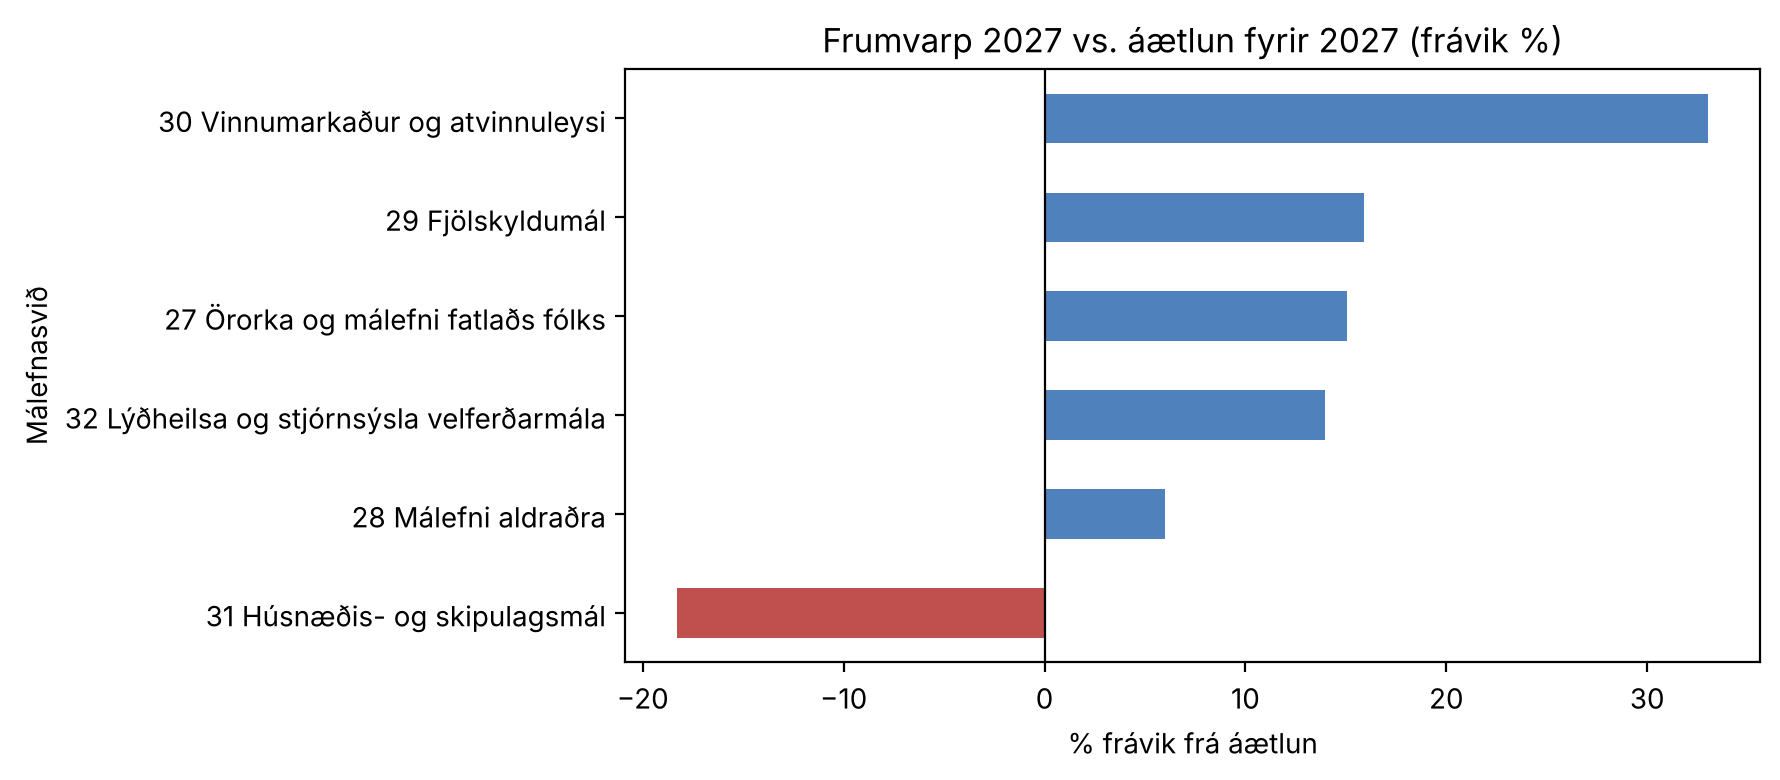

In [9]:
f27 = bera_saman(fel, 2027)["frávik_%"].sort_values()

ax = f27.plot(kind="barh", figsize=(9, 4), color=["#c0504d" if v < 0 else "#4f81bd" for v in f27])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Frumvarp 2027 vs. áætlun fyrir 2027 (frávik %)")
ax.set_xlabel("% frávik frá áætlun")
plt.tight_layout()
plt.show()

## 7. Spurning 3: Hvað breyttist á Alþingi?

Fjárlög 2026 voru lögð fram sem frumvarp í september 2025 og samþykkt í nóvember. Munurinn sýnir breytingar sem gerðar voru í meðförum þingsins.

In [10]:
bera_saman(fel, 2026)

,Frv. 2026: Frumvarp,Frv. 2027: Fjárlög,frávik_mkr,frávik_%
Málefnasvið,,,,
27 Örorka og málefni fatlaðs fólks,"132,621.8","141,293.6","8,671.8",6.5
29 Fjölskyldumál,"82,574.7","86,181.0","3,606.3",4.4
30 Vinnumarkaður og atvinnuleysi,"46,210.5","49,200.4","2,989.9",6.5
32 Lýðheilsa og stjórnsýsla velferðarmála,"12,973.8","14,493.5","1,519.7",11.7
31 Húsnæðis- og skipulagsmál,"25,901.9","25,913.1",11.2,0.0
28 Málefni aldraðra,"127,566.1","125,790.1","-1,776.0",-1.4


**Túlkun:** Í meðförum Alþingis hækkuðu framlög til **örorku um 8,7 ma.kr. (+6,5%)**, og vinnumarkaður og fjölskyldumál hækkuðu einnig. Húsnæðismál stóðu í stað og málefni aldraðra lækkuðu lítillega (−1,4%).

---
## Niðurstöður

1. **Fjárlög 2025 héldu ekki.** Raunútgjöld ríkisins urðu um 149 ma.kr. (~10%) umfram fjárlög, en stærsti hlutinn er bókhaldsleg breyting á lífeyrisskuldbindingum. Í félagsmálunum fóru flest svið fram úr, en **húsnæðismál nýttu 22% minna** en heimilað var.
2. **Áætlanir vanmeta.** Áætlunin fyrir 2027 var um 6% undir frumvarpinu ári síðar. Áætlunarár í fjármálaáætlun ætti því að lesa sem *neðri mörk* frekar en spá.
3. **Breytingar á Alþingi** á fjárlögum 2026 voru mestar í örorku (+8,7 ma.kr.).

## Frekari greiningar
- **Húsnæðismál 2025:** Hvaða liðir skýra vannýtinguna? (`bera_saman(..., eftir="Liður")`)
- **Vinnumarkaður 2027:** Er hækkunin í atvinnuleysisbótum eða í rekstri?
- **Áætlun fyrir 2028:** Báðar útgáfur innihalda áætlun fyrir 2028. Hve mikið breyttist hún á einu ári?
- **Sem MCP-verkfæri:** `bera_saman` er nánast tilbúið verkfæri í `server.py`, svo hægt sé að spyrja Claude beint um frávik.